In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1

In [110]:
booking_raw = pd.read_csv("./hotel_bookings.csv")
booking_raw.head(5)

,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled
0,HB0204,15.0,2.0,5.0,2.0,1.0,Deluxe,180000.0,Direct,0
1,HB0267,7.0,0.0,4.0,2.0,0.0,Standard,130000.0,Direct,0
2,HB0153,28.0,2.0,4.0,1.0,0.0,Standard,70000.0,Online,0
3,HB0010,30.0,2.0,3.0,2.0,2.0,Standard,130000.0,Online,0
4,HB0234,171.0,0.0,4.0,2.0,1.0,Standard,120000.0,Agency,0


In [111]:
len(booking_raw)

300

In [112]:
len(booking_raw.columns)

10

In [113]:
booking_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       300 non-null    object 
 1   lead_time        298 non-null    float64
 2   weekend_nights   298 non-null    float64
 3   weekday_nights   298 non-null    float64
 4   adults           298 non-null    float64
 5   children         298 non-null    float64
 6   room_type        296 non-null    object 
 7   daily_rate       296 non-null    float64
 8   booking_channel  296 non-null    object 
 9   is_canceled      300 non-null    int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 23.6+ KB


In [114]:
booking_raw.describe()

,lead_time,weekend_nights,weekday_nights,adults,children,daily_rate,is_canceled
count,298.000000,298.000000,298.000000,298.000000,298.000000,296.000000,300.000000
mean,47.677852,0.942953,2.953020,1.768456,0.422819,166587.837838,0.233333
std,51.739801,0.812425,1.448722,0.605873,0.683438,137061.828387,0.423659
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-10000.000000,0.000000
25%,8.000000,0.000000,2.000000,1.000000,0.000000,100000.000000,0.000000
50%,23.000000,1.000000,3.000000,2.000000,0.000000,120000.000000,0.000000
75%,78.750000,2.000000,4.000000,2.000000,1.000000,180000.000000,0.000000
max,179.000000,2.000000,5.000000,3.000000,2.000000,1000000.000000,1.000000


In [115]:
booking_raw.isna().sum()

booking_id         0
lead_time          2
weekend_nights     2
weekday_nights     2
adults             2
children           2
room_type          4
daily_rate         4
booking_channel    4
is_canceled        0
dtype: int64

In [116]:
missing_rate = booking_raw.isna().mean() * 100
print(missing_rate)

booking_id         0.000000
lead_time          0.666667
weekend_nights     0.666667
weekday_nights     0.666667
adults             0.666667
children           0.666667
room_type          1.333333
daily_rate         1.333333
booking_channel    1.333333
is_canceled        0.000000
dtype: float64


In [117]:
booking_raw['is_canceled'].value_counts()

is_canceled
0    230
1     70
Name: count, dtype: int64

In [118]:
booking_raw['is_canceled'].value_counts(normalize=True) * 100

is_canceled
0    76.666667
1    23.333333
Name: proportion, dtype: float64

정제가 필요한 항목

1. 결측치를 가진 열들
2. 수치형 열 중 음수를 가지고 있는 열들

# 2

In [119]:
booking_clean = booking_raw.copy()

In [120]:
len(booking_clean)

300

In [121]:
booking_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       300 non-null    object 
 1   lead_time        298 non-null    float64
 2   weekend_nights   298 non-null    float64
 3   weekday_nights   298 non-null    float64
 4   adults           298 non-null    float64
 5   children         298 non-null    float64
 6   room_type        296 non-null    object 
 7   daily_rate       296 non-null    float64
 8   booking_channel  296 non-null    object 
 9   is_canceled      300 non-null    int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 23.6+ KB


In [122]:
booking_clean.isna().sum()

booking_id         0
lead_time          2
weekend_nights     2
weekday_nights     2
adults             2
children           2
room_type          4
daily_rate         4
booking_channel    4
is_canceled        0
dtype: int64

In [123]:
print(f"lead time : \n{booking_clean.loc[booking_clean['lead_time'] < 0, ['booking_id','lead_time']]}\n")
print(f"weekend_nights : \n{booking_clean.loc[booking_clean['weekend_nights'] < 0, ['booking_id','weekend_nights']]}\n")
print(f"weekday_nights : \n{booking_clean.loc[booking_clean['weekday_nights'] < 0, ['booking_id','weekday_nights']]}\n")
print(f"adults : \n{booking_clean.loc[booking_clean['adults'] < 0, ['booking_id','adults']]}\n")
print(f"children : \n{booking_clean.loc[booking_clean['children'] < 0, ['booking_id','children']]}\n")
print(f"daily_rate : \n{booking_clean.loc[booking_clean['daily_rate'] <= 0, ['booking_id','daily_rate']]}\n")

lead time : 
    booking_id  lead_time
219     HB0041       -1.0

weekend_nights : 
    booking_id  weekend_nights
173     HB0042            -1.0

weekday_nights : 
   booking_id  weekday_nights
25     HB0043            -1.0

adults : 
    booking_id  adults
243     HB0044    -1.0

children : 
    booking_id  children
216     HB0045      -1.0

daily_rate : 
   booking_id  daily_rate
13     HB0046    -10000.0
38     HB0047         0.0



In [124]:
booking_clean.loc[booking_clean['lead_time'] < 0, 'adults'] = np.nan
booking_clean.loc[booking_clean['weekend_nights'] < 0, 'weekend_nights'] = np.nan
booking_clean.loc[booking_clean['weekday_nights'] < 0, 'weekday_nights'] = np.nan
booking_clean.loc[booking_clean['adults'] < 0, 'adults'] = np.nan
booking_clean.loc[booking_clean['children'] < 0, 'children'] = np.nan
booking_clean.loc[booking_clean['daily_rate'] <= 0, 'daily_rate'] = np.nan

In [125]:
booking_clean.isna().sum()

booking_id         0
lead_time          2
weekend_nights     3
weekday_nights     3
adults             4
children           3
room_type          4
daily_rate         6
booking_channel    4
is_canceled        0
dtype: int64

In [126]:
booking_clean.isna().sum().sum()

np.int64(29)

In [127]:
booking_clean['room_type'] = booking_clean['room_type'].fillna("Unknown")
booking_clean['booking_channel'] = booking_clean['booking_channel'].fillna("Unknown")
booking_clean['daily_rate'] = booking_clean['daily_rate'].fillna(booking_clean['daily_rate'].median())

In [128]:
booking_clean.isna().sum()

booking_id         0
lead_time          2
weekend_nights     3
weekday_nights     3
adults             4
children           3
room_type          0
daily_rate         0
booking_channel    0
is_canceled        0
dtype: int64

In [129]:
booking_clean = booking_clean.dropna(subset=['lead_time','weekend_nights','weekday_nights','adults','children'])

In [130]:
booking_clean.isna().sum()

booking_id         0
lead_time          0
weekend_nights     0
weekday_nights     0
adults             0
children           0
room_type          0
daily_rate         0
booking_channel    0
is_canceled        0
dtype: int64

In [131]:
len(booking_clean)

285

In [132]:
(booking_clean.loc[:,['lead_time','weekend_nights','weekday_nights','adults','children']] >= 0 ).all()

lead_time         True
weekend_nights    True
weekday_nights    True
adults            True
children          True
dtype: bool

In [133]:
( booking_clean.loc[:,'daily_rate'] > 0 ).all()

np.True_

일수·인원수 임의 대체의 영향 - 임의로 값을 대체하면 전체 통계에 원치 않은 영향을 줄 수 있음.

요금 대체값 선택 이유 - 평균으로 대체하면 그 값이 극단치의 영향을 받기 쉬우므로, 사분위상 중간에 위치한 가격으로 대체하여 이러한 극단치의 영향을 덜 받을 수 있다.

`'Unknown'` 사용 이유 - 어느 한 쪽으로 대체를 한다면 데이터 통계에 원치 않은 영향을 줄 수 있기 때문에 결측 상태를 그대로 두거나 삭제하는 대신 새로운 Unknown 범주로 데이터를 분류하여 데이터 통계에 미치는 영향을 줄인다

# 3

In [134]:
q1 = booking_clean['daily_rate'].quantile(0.25)
q3 = booking_clean['daily_rate'].quantile(0.75)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr

In [135]:
print(booking_clean.loc[(booking_clean['daily_rate'] < lower_bound),'daily_rate'].value_counts().sum())

0


In [136]:
print( booking_clean.loc[(booking_clean['daily_rate'] > upper_bound),'daily_rate'].value_counts().sum() )

26


In [137]:
print(( booking_clean.loc[(booking_clean['daily_rate'] > upper_bound),'daily_rate'].value_counts().sum() / booking_clean['daily_rate'].value_counts().sum() ) * 100)

9.12280701754386


In [138]:
booking_clean.loc[(booking_clean['daily_rate'] > upper_bound),['booking_id','room_type','daily_rate']]

,booking_id,room_type,daily_rate
7,HB0110,Suite,550000.0
8,HB0006,Suite,450000.0
14,HB0183,Suite,350000.0
32,HB0034,Suite,640000.0
37,HB0091,Suite,800000.0
57,HB0093,Suite,1000000.0
67,HB0257,Suite,420000.0
81,HB0155,Suite,560000.0
85,HB0115,Suite,480000.0
98,HB0275,Suite,580000.0


경게값 제한을 둔 데이터는 새로운 열 daily_rate_processed에 저장 하였고 원래 값을 유지한다는 기존 daily_rate에서 아무 처리를 하지 않는 것과 같습니다

따라서 '원래값 유지'와 '경계값 제한' 간의 비교는 기존 daily_rate와 새로운 daily_rate_processed의 두 열을 비교하는 것으로 합니다.

과제에 따라 daily_rate_processed 열에 경계값 제한으로 처리한 데이터를 담았지만 원래 값 유지가 더 좋은 판단이라고 생각합니다

원래 값 유지가 더 좋은 처리라 생각하는 근거

- 하한보다 낮은 데이터는 없었고, 상한보다 높은 데이터는 room_type이 하나의 Unknown을 제외하면 나머지 모두 suite 였다.
- 이는 방의 가격이 이상하게 비싸다기 보단 suite 등급에 따른 높은 가격이 부여된 방이라는 해석이 더 맞다고 생각한다

IQR 범위 이탈에 대한 오류 판정 설명



In [139]:
booking_clean['daily_rate_processed'] = booking_clean['daily_rate'].clip(lower_bound,upper_bound)
booking_clean['daily_rate_processed'].describe()

count       285.000000
mean     144912.280702
std       68467.191871
min       70000.000000
25%      100000.000000
50%      120000.000000
75%      180000.000000
max      300000.000000
Name: daily_rate_processed, dtype: float64

In [140]:
booking_clean['daily_rate'].describe()

count        285.000000
mean      166947.368421
std       136439.175564
min        70000.000000
25%       100000.000000
50%       120000.000000
75%       180000.000000
max      1000000.000000
Name: daily_rate, dtype: float64

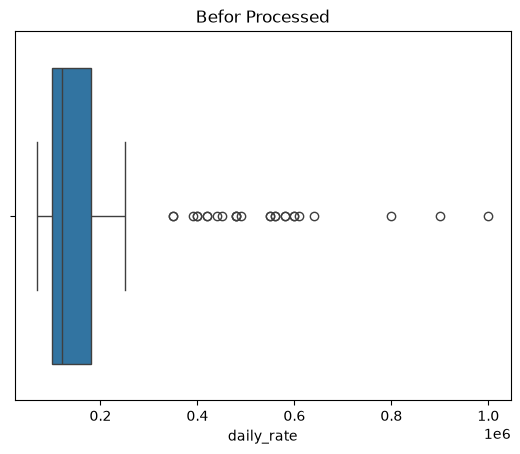

In [141]:
sns.boxplot(data = booking_clean,x='daily_rate')
plt.title("Befor Processed")
plt.show()

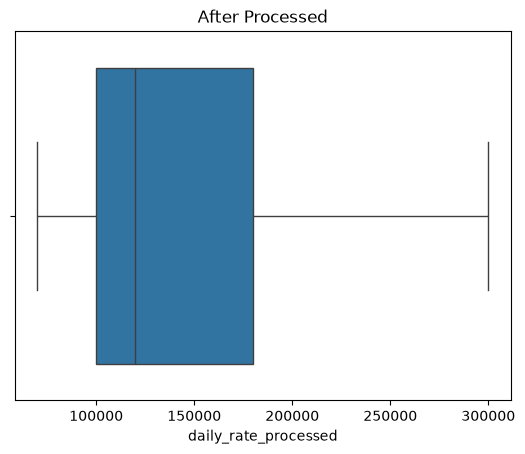

In [142]:
sns.boxplot(data = booking_clean,x='daily_rate_processed')
plt.title("After Processed")
plt.show()

# 4

In [143]:
booking_clean['total_nights'] = booking_clean['weekday_nights'] + booking_clean['weekend_nights']
booking_clean['total_guests'] = booking_clean['adults'] + booking_clean['children']
booking_clean['estimated_room_amount'] = booking_clean['daily_rate'] * booking_clean['total_nights']
booking_clean['lead_time_group'] = pd.cut(booking_clean['lead_time'],bins=[-1,7,30,np.inf],labels=['Within7Days','8to30Days','Over30Days'])
display(booking_clean.loc[:,['total_nights','total_guests','estimated_room_amount','lead_time_group']])

,total_nights,total_guests,estimated_room_amount,lead_time_group
0,7.0,3.0,1260000.0,8to30Days
1,4.0,2.0,520000.0,Within7Days
2,6.0,1.0,420000.0,8to30Days
3,5.0,4.0,650000.0,8to30Days
4,4.0,3.0,480000.0,Over30Days
...,...,...,...,...
295,3.0,2.0,210000.0,8to30Days
296,3.0,2.0,390000.0,Over30Days
297,4.0,2.0,440000.0,Over30Days
298,3.0,3.0,300000.0,8to30Days


In [144]:
booking_clean[(booking_clean['total_nights']==0) | (booking_clean['total_guests']==0)]['booking_id']

169    HB0052
251    HB0054
261    HB0053
271    HB0051
Name: booking_id, dtype: object

In [145]:
booking_clean = booking_clean.drop(index=booking_clean[(booking_clean['total_nights']==0) | (booking_clean['total_guests']==0)].index)

In [146]:
len(booking_clean)

281

In [147]:
booking_clean.loc[:,['lead_time','lead_time_group']].head(10)

,lead_time,lead_time_group
0,15.0,8to30Days
1,7.0,Within7Days
2,28.0,8to30Days
3,30.0,8to30Days
4,171.0,Over30Days
5,143.0,Over30Days
6,91.0,Over30Days
7,27.0,8to30Days
8,6.0,Within7Days
9,127.0,Over30Days


- 네 파생변수를 운영팀이 어떻게 활용할 수 있는지 각각 한 문장으로 작성합니다.

total nights로 각 예약의 총 숙박일수를 파악할 수 있다.
total guest로 각 예약의 총 숙박 인원을 파악할 수 있다.
estimated room amount로 각 예약의 총 지불 숙박 요금을 예상해 볼 수 있다.
lead time group으로 선행일 수의 기준에 따른 분류를 통해 데이터를 더 분석적으로 접근할 수 있다.

- `estimated_room_amount`를 실제 매출이라고 부를 수 없는 이유를 작성합니다.

is_canceled 가 1인 데이터, 즉 취소된 예약에 대해서도 선행적으로 값을 계산해 놓았기 때문에 총 매출에 포함되는지 이 값만으론 알 수 없다.

\+ 예상 객실 요금에는 실제 취소·환불·추가 요금 등이 반영되어 있지 않는다.

# 5

In [148]:
selected = booking_clean[( booking_clean['is_canceled'] == 0 ) & ( booking_clean['lead_time'] >= 60 ) & ( booking_clean['total_nights'] >= 3 ) & ( booking_clean['booking_channel'].isin(['Online','Agency']) )]

In [149]:
selected.loc[:,['booking_id','booking_channel','lead_time','total_nights','total_guests','estimated_room_amount']]

,booking_id,booking_channel,lead_time,total_nights,total_guests,estimated_room_amount
4,HB0234,Agency,171.0,4.0,3.0,480000.0
13,HB0046,Online,137.0,5.0,1.0,600000.0
20,HB0079,Agency,100.0,3.0,1.0,210000.0
24,HB0105,Online,78.0,4.0,1.0,440000.0
26,HB0282,Online,76.0,5.0,2.0,400000.0
39,HB0074,Online,75.0,3.0,2.0,240000.0
41,HB0077,Agency,150.0,3.0,2.0,750000.0
44,HB0078,Online,80.0,3.0,4.0,420000.0
46,HB0235,Agency,164.0,5.0,1.0,550000.0
50,HB0181,Agency,79.0,7.0,2.0,1260000.0


In [150]:
selected.sort_values('estimated_room_amount',ascending=False).head(10)

,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled,daily_rate_processed,total_nights,total_guests,estimated_room_amount,lead_time_group
198,HB0028,154.0,0.0,4.0,1.0,1.0,Unknown,480000.0,Online,0,300000.0,4.0,2.0,1920000.0,Over30Days
149,HB0084,157.0,2.0,4.0,2.0,1.0,Deluxe,240000.0,Online,0,240000.0,6.0,3.0,1440000.0,Over30Days
50,HB0181,79.0,2.0,5.0,2.0,0.0,Deluxe,180000.0,Agency,0,180000.0,7.0,2.0,1260000.0,Over30Days
292,HB0122,133.0,1.0,3.0,2.0,0.0,Deluxe,250000.0,Online,0,250000.0,4.0,2.0,1000000.0,Over30Days
52,HB0240,115.0,2.0,5.0,1.0,0.0,Standard,130000.0,Online,0,130000.0,7.0,1.0,910000.0,Over30Days
78,HB0067,60.0,0.0,5.0,2.0,0.0,Deluxe,180000.0,Online,0,180000.0,5.0,2.0,900000.0,Over30Days
232,HB0292,154.0,0.0,5.0,2.0,2.0,Deluxe,180000.0,Online,0,180000.0,5.0,4.0,900000.0,Over30Days
93,HB0225,84.0,2.0,5.0,1.0,1.0,Standard,120000.0,Agency,0,120000.0,7.0,2.0,840000.0,Over30Days
41,HB0077,150.0,1.0,2.0,2.0,0.0,Deluxe,250000.0,Agency,0,250000.0,3.0,2.0,750000.0,Over30Days
140,HB0116,92.0,2.0,2.0,2.0,0.0,Deluxe,180000.0,Online,0,180000.0,4.0,2.0,720000.0,Over30Days


In [151]:
len(selected)

35

In [152]:
print(selected['estimated_room_amount'].sum())

21510000.0


In [153]:
print( (selected['is_canceled'] == 0 ).all() & ( selected['lead_time'] >= 60 ).all() & ( selected['total_nights'] >= 3 ).all() & ( selected['booking_channel'].isin(['Online','Agency']).all() ))

True


# 6
남은 할 것 : 막대에 취소율 표시

lead_time 분포

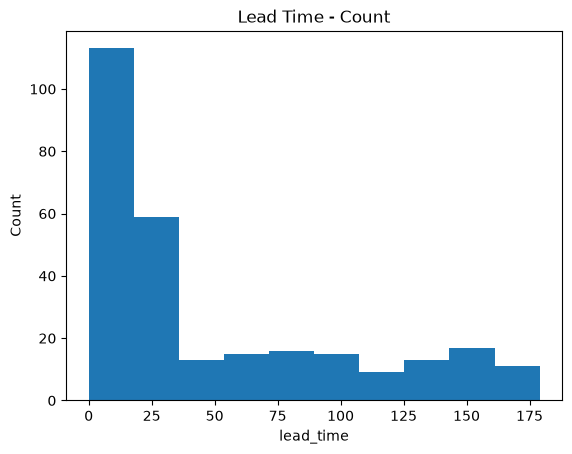

In [154]:
plt.hist(x=booking_clean['lead_time'],bins=10)
plt.title('Lead Time - Count')
plt.xlabel('lead_time')
plt.ylabel('Count')
plt.show()

이 자료로 보아 선행 기간이 길 수록 예약한 인원 수도 줄어드는 경향을 파악할 수 있다.

그리고 한 달 이내의 선행 기간에 예약한 사람의 인원수가 약 160명으로 보이며 이는 전체 인원의 약 절반 정도를 차지한다.

booking_channel 별 취소율

In [155]:
booking_clean['booking_channel'].value_counts()

booking_channel
Online     141
Direct      83
Agency      53
Unknown      4
Name: count, dtype: int64

In [156]:
booking_clean.groupby('booking_channel')['is_canceled'].value_counts()

booking_channel  is_canceled
Agency           0              44
                 1               9
Direct           0              70
                 1              13
Online           0              99
                 1              42
Unknown          0               3
                 1               1
Name: count, dtype: int64

In [157]:
booking_clean.groupby('booking_channel')['is_canceled'].mean() * 100

booking_channel
Agency     16.981132
Direct     15.662651
Online     29.787234
Unknown    25.000000
Name: is_canceled, dtype: float64

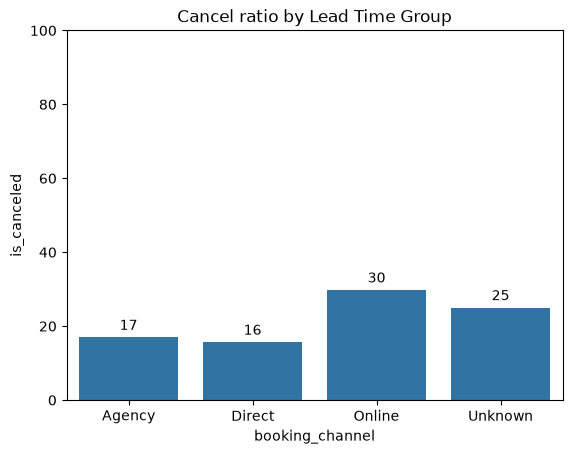

In [158]:
cancel_ratio_by_booking_channel = booking_clean.groupby('booking_channel')['is_canceled'].mean() * 100
ax = sns.barplot(cancel_ratio_by_booking_channel)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Cancel ratio by Lead Time Group")
plt.ylim(0,100)
plt.show()

Unknown의 경우도 예약 취소율이 2등으로 적잖게 높은 경향을 보이고 있지만 어느 채널인지 알 수 없으므로 해석을 보류한다.

그렇게 하면 Online으로 예약한 사람이 가장 높은 취소 비율을 보이며 Direct로 예약한 사람의 취소율이 가장 낮았다.

lead_time_group 별 취소율

In [159]:
booking_clean['lead_time_group'].value_counts(ascending=True)

lead_time_group
Within7Days     69
8to30Days      100
Over30Days     112
Name: count, dtype: int64

In [160]:
booking_clean.groupby('lead_time_group')['is_canceled'].value_counts()

C:\Users\icesn\AppData\Local\Temp\ipykernel_22860\3688533219.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  booking_clean.groupby('lead_time_group')['is_canceled'].value_counts()


lead_time_group  is_canceled
Within7Days      0              57
                 1              12
8to30Days        0              87
                 1              13
Over30Days       0              72
                 1              40
Name: count, dtype: int64

In [161]:
booking_clean.groupby('lead_time_group')['is_canceled'].mean() * 100

C:\Users\icesn\AppData\Local\Temp\ipykernel_22860\691957764.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  booking_clean.groupby('lead_time_group')['is_canceled'].mean() * 100


lead_time_group
Within7Days    17.391304
8to30Days      13.000000
Over30Days     35.714286
Name: is_canceled, dtype: float64

C:\Users\icesn\AppData\Local\Temp\ipykernel_22860\1067091491.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cancel_ratio_by_lead_time_group = booking_clean.groupby('lead_time_group')['is_canceled'].mean() * 100


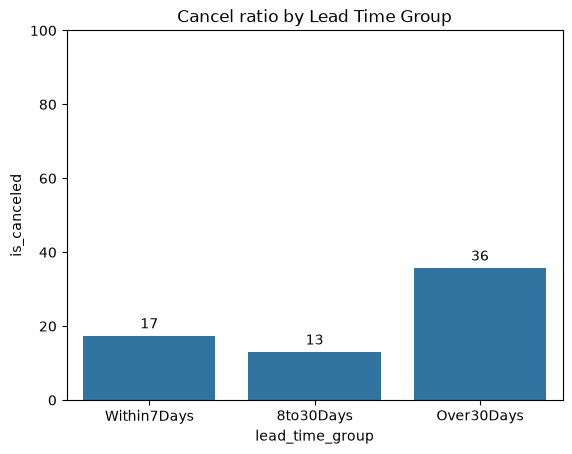

In [162]:
cancel_ratio_by_lead_time_group = booking_clean.groupby('lead_time_group')['is_canceled'].mean() * 100
ax = sns.barplot(cancel_ratio_by_lead_time_group)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Cancel ratio by Lead Time Group")
plt.ylim(0,100)
plt.show()

순서상으론 30일 이상 남은 경우 취소율이 가장 높고 그 다음으론 7일 이내, 마지막으론 8일 이상 30일 이내의 그룹이다

# 7

## 운영팀에 전달할 수 있는 결과 요약

주요 데이터 품질에 대해서 전체 데이터 300개 중 데이터에 결측 및 이상치가 존재하는 데이터로 29개가 검출되었다. 이러한 데이터는 모두 제거하기엔 약 10퍼센트 가량을 차지 하기에 가격,객실타입,예약 경로의 데이터는 다른 값으로 대체하였고, 그 외 수치형의 결측 데이터를 포함하는 행은 제거를 하여 약 280개 가량의 데이터를 이용하였다. 차트를 통해 예약 취소의 특성을 살펴보면 선행 예약 기간 구간 중 30일이 넘을 경우의 취소율이 가장 높았고, 예약 채널 중엔 온라인으로 예약한 사람의 취소율이 가장 높았다. 사전 확인 대상의 예약 건수는 35건 이었다. 이들은 아직 취소된 예약은 아니지만 예정 입실일보다 60일 이상 전에 접수 되었고, 다수가 Online을 통해 예약했기 때문에 적잖은 사람이 예약을 취소할 수도 있을 것으로 예측해 볼 수 있다. 운영팀이 추가로 검토하면 좋을 사항은 객실 유형이나 가격에 따른 예약 취소 비율을 살펴보았음 한다. 분석의 한계로는 단순한 수치적 데이터를 통해 사람의 예약 취소 심리를 예측해야 하기 때문에 그러기 위한 데이터 가지 수나 양이 부족했고 추가로 필요한 데이터 한가지로는 실제로 투숙을 마친 인원들의 데이터를 조사하였음 좋겠다고 생각한다.